# Study area delineation

The study area is the convex hull of all LCS station locations, buffered by `buffer_dist` (2 km by default) to include the urban--rural transition zone.

In [1]:
import geopandas as gpd

In [2]:
lcs_stations_gdf_filepath = "../data/interim/lcs-stations.gpkg"
buffer_dist = 2000

dst_filepath = "../data/processed/zurich-lcs-extent.gpkg"

In [3]:
# Parameters
lcs_stations_gdf_filepath = "data/interim/lcs-stations.gpkg"
buffer_dist = 2000
dst_filepath = "data/processed/zurich-lcs-extent.gpkg"


## Load LCS stations

In [4]:
lcs_stations_gdf = gpd.read_file(lcs_stations_gdf_filepath)
lcs_stations_gdf.head()

,index,geometry
0,A10,POINT (2678150 1248450)
1,A7,POINT (2677937 1250077)
2,B12,POINT (2678750 1247612)
3,B3,POINT (2678244 1252038)
4,B6,POINT (2678392 1250579)


## Buffered convex hull

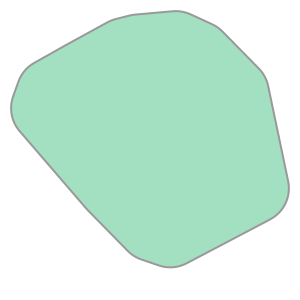

In [5]:
lcs_extent_gser = lcs_stations_gdf.geometry.union_all().convex_hull.buffer(buffer_dist)
lcs_extent_gser

## Save extent

In [6]:
gpd.GeoSeries([lcs_extent_gser], crs=lcs_stations_gdf.crs).to_file(dst_filepath)
dst_filepath

'data/processed/zurich-lcs-extent.gpkg'